<a href="https://colab.research.google.com/github/sitiekbal/CapstnPro_Econ.Analysis/blob/main/Capstone_Project_Economic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd

url = 'https://raw.githubusercontent.com/sitiekbal/CapstnPro_Econ.Analysis/refs/heads/main/Global%20Economic%20Data.csv'
df = pd.read_csv(url)
df.head()

,Country,Year,GDP (in Trillions USD),GDP per Capita (in USD),Inflation Rate (%),Population (in Millions),Population Growth Rate (%),Urban Population (%),Life Expectancy (Years),Healthcare Expenditure per Capita (USD),...,Poverty Rate (%),Number of International Visitors (in Millions),Tourism Revenue (in Billion USD),Agricultural Land (%),Unemployment Rate (%),Labor Force Participation Rate (%),"Crime Rate (per 100,000)",Corruption Perception Index,Freedom of Press Index,Voting Participation Rate (%)
0,USA,2000,20.87,65455.0,2.28,330.34,0.58,83.42,78.39,11209.00,...,10.98,80.80,210.98,42.37,3.55,65.52,287.40,67.41,45.27,68.81
1,Russia,2000,1.64,10923.0,3.25,141.81,0.10,72.67,69.91,534.45,...,12.89,24.70,36.47,12.53,4.63,57.54,497.50,30.90,146.10,65.00
2,Canada,2000,1.65,47932.0,1.96,36.63,0.90,79.54,84.60,5113.50,...,9.46,22.33,29.52,7.22,5.43,65.06,795.20,74.74,16.42,63.00
3,China,2000,13.64,10060.0,2.43,1446.93,0.31,58.56,76.09,459.00,...,2.04,62.20,115.80,54.00,3.68,63.13,102.90,41.75,185.32,72.14
4,India,2000,2.98,2102.1,4.87,1313.76,1.04,34.09,68.78,76.07,...,22.25,11.25,29.12,57.60,7.31,52.10,245.25,40.12,136.36,67.65


## Comparative Analysis: Top-Performing Countries by GDP and HDI (2023)

This comparative analysis focuses on the top-performing nations in our global panel cohort based on two standard pillars of progress: **Gross Domestic Product (GDP)** representing overall economic scale, and the **Human Development Index (HDI)** representing structural living standards, education, and longevity.

### 1. The High-Wealth Leaders: USA, Australia, and Canada
* **USA:** The largest absolute economy ($20.87T in 2023) with a high GDP per Capita (~$65,455) and an HDI of **0.97**. It shows strong output scale but historically higher domestic disparities compared to counterparts.
* **Australia:** Possesses a highly developed resource-based and service economy with a strong GDP per Capita (~$51,304) and an HDI of **0.95**.
* **Canada:** Represents a high-wealth baseline (~$44,804 GDP per capita) with robust social indicators reflecting an HDI score of **0.92**.

### 2. Key Insights
* **HDI Stability vs. Economic Growth:** While GDP and GDP per capita can fluctuate with business cycles, the Human Development Index remains highly stable and rigid over time, reflecting long-term investments in healthcare infrastructure and educational access.
* **Decoupling Trends:** These high-performing nations are progressively decoupled from absolute emission increases, maintaining modern industrial outputs while expanding clean energy and service-based sectors.

In [23]:
import pandas as pd

# Filter for 2023 (the latest year in the dataset)
latest_data = df[df['Year'] == 2023]

# Sort by GDP per capita to identify top performers
top_performers = latest_data.sort_values(by='GDP per Capita (in USD)', ascending=False).head(3)

# Select comparison columns
comparison_cols = [
    'Country',
    'GDP (in Trillions USD)',
    'GDP per Capita (in USD)',
    'Human Development Index (HDI)',
    'Life Expectancy (Years)',
    'Renewable Energy Share (%)'
]

comparison_df = top_performers[comparison_cols].reset_index(drop=True)

print("=== COMPARISON OF TOP-PERFORMING COUNTRIES (2023) ===")
display(comparison_df)

=== COMPARISON OF TOP-PERFORMING COUNTRIES (2023) ===


,Country,GDP (in Trillions USD),GDP per Capita (in USD),Human Development Index (HDI),Life Expectancy (Years),Renewable Energy Share (%)
0,USA,21.17,63245.0,0.90,80.68,16.30
1,Australia,1.27,51304.0,0.95,83.40,23.00
2,Canada,1.73,44804.0,0.92,79.17,68.47


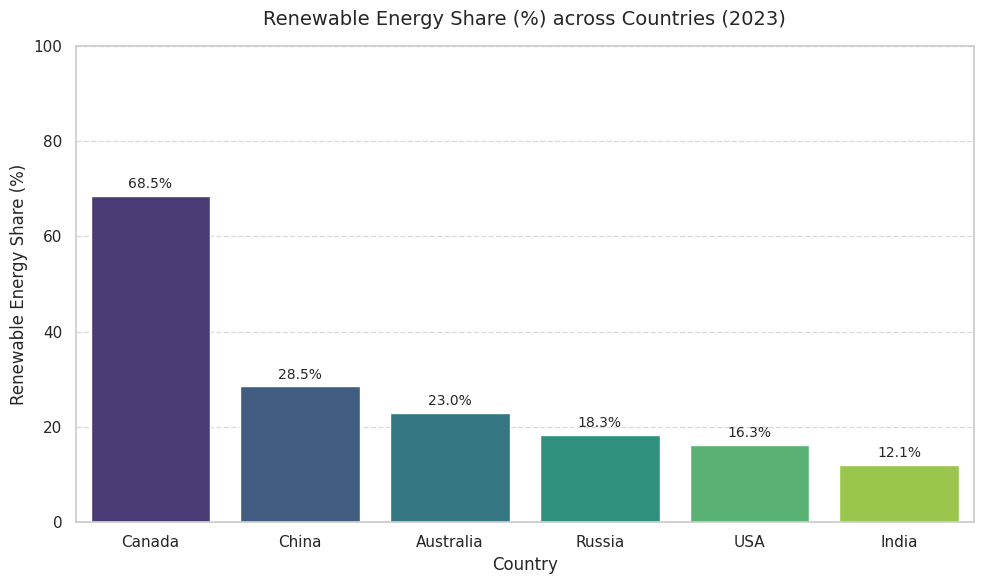

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for the latest year (2023)
latest_df = df[df['Year'] == 2023].sort_values(by='Renewable Energy Share (%)', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=latest_df,
    x='Country',
    y='Renewable Energy Share (%)',
    palette='viridis',
    hue='Country',
    legend=False
)

plt.title('Renewable Energy Share (%) across Countries (2023)', fontsize=14, pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Renewable Energy Share (%)', fontsize=12)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display data values on top of the bars
for index, row in enumerate(latest_df.itertuples()):
    plt.text(index, row._17 + 1, f"{row._17:.1f}%", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('renewable_energy_comparison_2023.png', dpi=150)
plt.show()

Overall Correlation Coefficient: 0.2621

Correlation by Country:


/tmp/ipykernel_907/2970983962.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  country_corrs = df.groupby('Country').apply(lambda g: g['GDP per Capita (in USD)'].corr(g['Renewable Energy Share (%)'])).reset_index()


,Country,Correlation Coefficient
5,USA,0.144639
3,India,0.019044
1,Canada,-0.043719
2,China,-0.085811
0,Australia,-0.203796
4,Russia,-0.320941


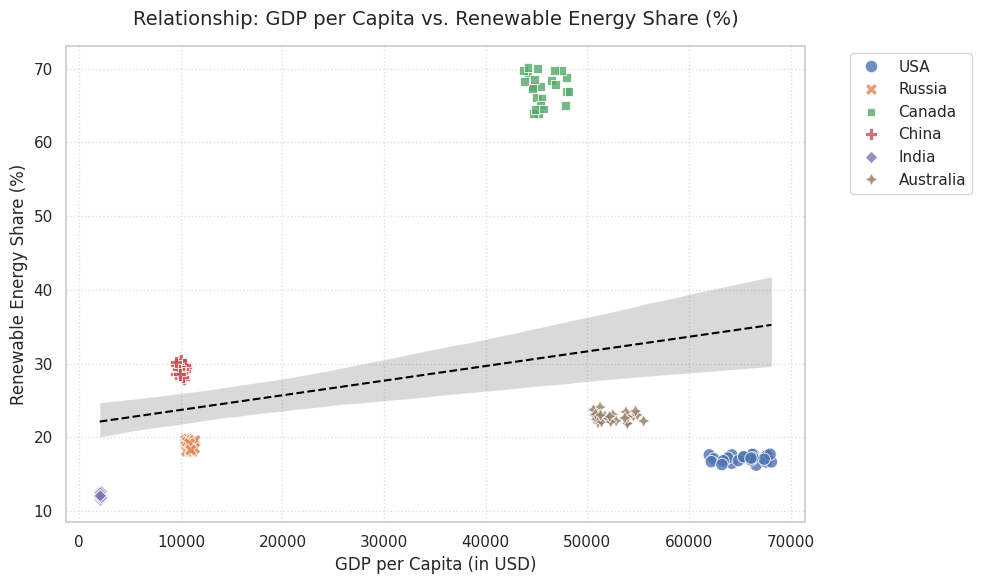

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate overall correlation
overall_corr = df['GDP per Capita (in USD)'].corr(df['Renewable Energy Share (%)'])
print(f"Overall Correlation Coefficient: {overall_corr:.4f}")

# Calculate correlation by country
country_corrs = df.groupby('Country').apply(lambda g: g['GDP per Capita (in USD)'].corr(g['Renewable Energy Share (%)'])).reset_index()
country_corrs.columns = ['Country', 'Correlation Coefficient']
print("\nCorrelation by Country:")
display(country_corrs.sort_values(by='Correlation Coefficient', ascending=False))

# Plot the relationship
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='GDP per Capita (in USD)',
    y='Renewable Energy Share (%)',
    hue='Country',
    style='Country',
    s=80,
    alpha=0.8
)

# Add an overall regression line to see the macro trend
sns.regplot(
    data=df,
    x='GDP per Capita (in USD)',
    y='Renewable Energy Share (%)',
    scatter=False,
    color='black',
    line_kws={'linestyle': '--', 'linewidth': 1.5, 'label': 'Overall Trend'}
)

plt.title('Relationship: GDP per Capita vs. Renewable Energy Share (%)', fontsize=14, pad=15)
plt.xlabel('GDP per Capita (in USD)', fontsize=12)
plt.ylabel('Renewable Energy Share (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('gdp_vs_renewables_correlation.png', dpi=150)
plt.show()

### Summary of Findings: GDP per Capita vs. Renewable Energy Share

* **Overall Macro Trend:** A weak positive correlation of **0.2621** indicates that at a global level, higher GDP per capita is gently associated with a larger share of renewable energy. However, this is heavily influenced by country-specific policies rather than a guaranteed economic mechanism.
* **National Variations:**
  * **USA (+0.14) & India (+0.02):** Moving slightly or staying flat, showing that economic expansion is still accompanied by highly mixed energy choices.
  * **Canada (-0.04):** Flat relationship. Canada possesses a massive, legacy hydroelectric network that keeps renewable share high ($>68\%$) regardless of year-to-year GDP fluctuations.
  * **Australia (-0.20) & Russia (-0.32):** Moderate negative correlation. These resource-dependent, fossil-exporting economies historically tied their economic expansions to carbon-heavy industrial and mineral sectors.

In [26]:
# Clean recalculation without DeprecationWarnings
country_corrs_clean = (
    df.groupby('Country', as_index=False)
    .apply(lambda g: pd.Series({
        'Correlation Coefficient': g['GDP per Capita (in USD)'].corr(g['Renewable Energy Share (%)'])
    }), include_groups=False)
)

display(country_corrs_clean.sort_values(by='Correlation Coefficient', ascending=False))

,Country,Correlation Coefficient
5,USA,0.144639
3,India,0.019044
1,Canada,-0.043719
2,China,-0.085811
0,Australia,-0.203796
4,Russia,-0.320941
